# VIBE robust-prune runs: viewer for the old graph format

Viewer for runs whose graphs were written **before** the uncovered counts were added: adjacency lines `source [neighbor1, neighbor2, ...]`. For runs in the current format, `source [(neighbor, uncovered), ...]`, use `vibe_robust_prune.ipynb`, which also plots how coverage grows edge by edge.

Nothing is computed here except plots: the runs come from `vibe_pipeline.py` (`sbatch src/vibe_pipeline.slurm <dataset>`), which downloads the dataset, builds the same-spectrum Gaussian, the two robust-prune graphs and the results table in `GRAPH_DIR`. Old runs have no `-meta.json`: their number of points comes from the results table once a run has finished, and the Gaussian's sample spectrum is regenerated from the saved dataset spectrum (n × d float32 in memory, saved for next time).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from paths import RESULTS_DIR
from vibe import coverage_curve, find_runs, gaussian_spectrum, read_graph, run_info

GRAPH_DIR = RESULTS_DIR / "vibe_graphs"     # where vibe_pipeline.py wrote its runs (its --graph-dir)
SEED = 0                 # the run's --seed (only used to regenerate a Gaussian spectrum that was not saved)
PRUNE_ALPHA = 1.0        # the run's --alpha
PLOT_PARTIAL = True      # also plot graphs that are still being built (sources done so far)
COLORS = {"dataset": "C0", "gaussian": "C1"}   # matplotlib's default colors, the same in every panel

runs = [run_info(GRAPH_DIR, name, PRUNE_ALPHA) for name in find_runs(GRAPH_DIR)]
print(f"{len(runs)} run(s) in {GRAPH_DIR}: {', '.join(r['name'] for r in runs)}")

4 run(s) in /scratch/pa2439/multi-vector-search/results/vibe_graphs: agnews-mxbai-1024-euclidean, arxiv-nomic-768-normalized, simplewiki-openai-3072-normalized, yahoo-minilm-384-normalized


## Runs

In [2]:
def progress(done, n):
    return f"{done:,}" + (f" / {n:,} ({100 * done / n:.0f}%)" if n else "")

pd.DataFrame([{
    "run": r["name"], "n": r["n"], "d": r["d"],
    "d_eff": r["lam"].sum() ** 2 / (r["lam"] ** 2).sum() if r["lam"] is not None else None,
    "dataset graph": progress(r["graphs"]["dataset"][1], r["n"]),
    "Gaussian graph": progress(r["graphs"]["gaussian"][1], r["n"]),
    "finished": r["results"] is not None,
} for r in runs]).style.format({"n": "{:,.0f}", "d": "{:,.0f}", "d_eff": "{:.1f}"}, na_rep="–").hide(axis="index")

run,n,d,d_eff,dataset graph,Gaussian graph,finished
agnews-mxbai-1024-euclidean,"769,382","1,024",124.9,"769,382 / 769,382 (100%)","769,382 / 769,382 (100%)",True
arxiv-nomic-768-normalized,"1,344,643",768,63.3,"1,344,643 / 1,344,643 (100%)","1,344,643 / 1,344,643 (100%)",True
simplewiki-openai-3072-normalized,"260,372","3,072",206.7,"260,372 / 260,372 (100%)","260,372 / 260,372 (100%)",True
yahoo-minilm-384-normalized,"677,305",384,151.0,"677,305 / 677,305 (100%)","677,305 / 677,305 (100%)",True


## Results

Finished runs only (`<name>-results.csv`). In-degree and reciprocity cover complete graphs.

In [3]:
finished = [r["results"].assign(run=r["name"]) for r in runs if r["results"] is not None]
if finished:
    table = pd.concat(finished, ignore_index=True).set_index(["run", "dataset"])
    display(table.style.format(
        {"n": "{:,}", "d_eff": "{:.1f}", "d_eff / d": "{:.3f}", "sources": "{:,}", "edges": "{:,}",
         "out mean": "{:.1f}", "out median": "{:.0f}", "out p99": "{:.0f}", "out max": "{:.0f}",
         "in median": "{:.0f}", "in p99": "{:.0f}", "in max": "{:.0f}", "in zero": "{:,.0f}",
         "reciprocity": "{:.3f}"}, na_rep="–"))
else:
    print("no finished runs yet")

## Per run

For each run: spectrum, out-degree distribution. Reading a graph parses its whole adjacency list (about a minute for 1M sources).

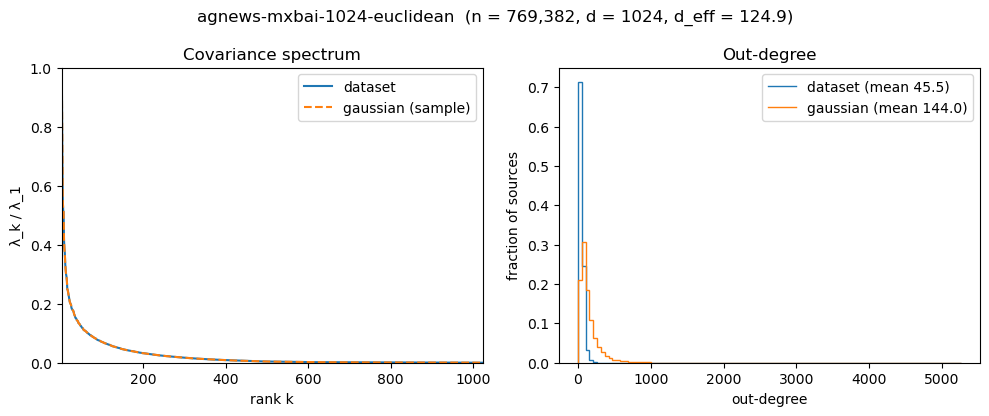

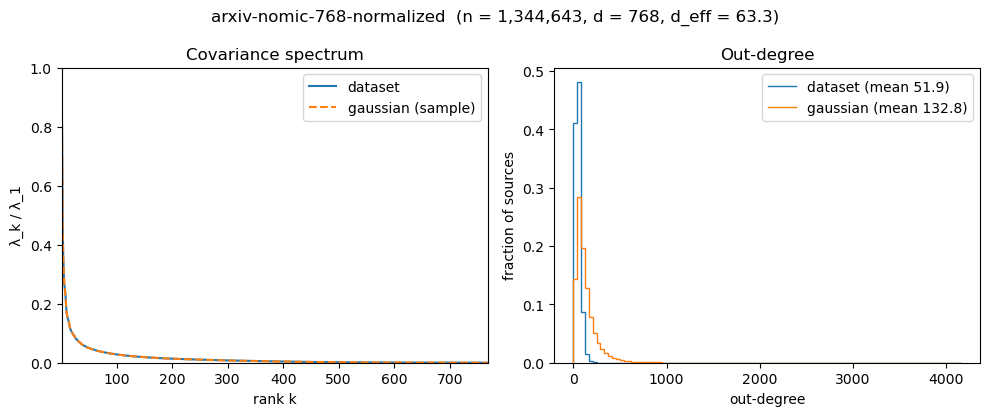

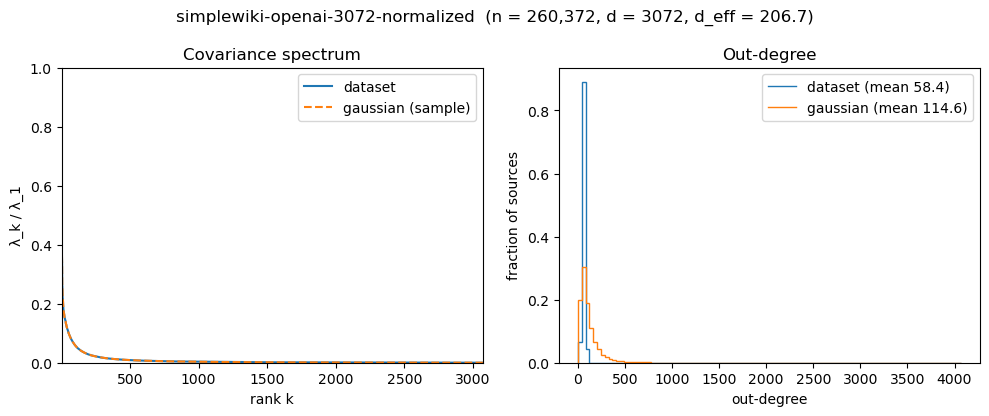

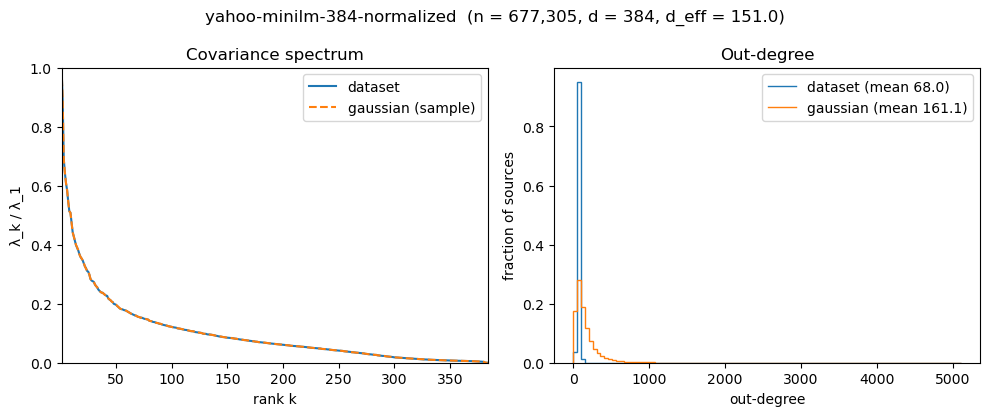

In [4]:
for r in runs:
    name, n, d, lam = r["name"], r["n"], r["d"], r["lam"]
    lam_syn = gaussian_spectrum(GRAPH_DIR, name, lam, n, SEED)
    graphs = {}
    for label, (adj_path, done) in r["graphs"].items():
        if done and (PLOT_PARTIAL or done == n):
            graphs[label] = read_graph(adj_path, uncovered=True)

    plt.figure(figsize=(10, 4.2))
    plt.subplot(1, 2, 1)
    if lam is not None:
        k = np.arange(1, d + 1)
        plt.plot(k, lam / lam[0], color=COLORS["dataset"], label="dataset")
        if lam_syn is not None:
            plt.plot(k, lam_syn / lam_syn[0], color=COLORS["gaussian"], ls="--", label="gaussian (sample)")
        plt.xlim(1, d)
        plt.legend()
    plt.ylim(0, 1)
    plt.xlabel("rank k")
    plt.ylabel("λ_k / λ_1")
    plt.title("Covariance spectrum")

    plt.subplot(1, 2, 2)
    degrees = {label: np.fromiter((len(nb) for nb, _ in hoods.values()), dtype=np.int64)
               for label, hoods in graphs.items()}
    if degrees:
        hi = max(x.max() for x in degrees.values())
        bins = np.arange(0, hi + 2) if hi <= 200 else np.linspace(0, hi + 1, 101)
        for label, x in degrees.items():
            counts, edges = np.histogram(x, bins=bins)
            done = r["graphs"][label][1]
            note = "" if done == n else f", {done:,} sources so far"
            plt.stairs(counts / len(x), edges, color=COLORS[label], label=f"{label} (mean {x.mean():.1f}{note})")
        plt.legend()
    plt.xlabel("out-degree")
    plt.ylabel("fraction of sources")
    plt.title("Out-degree")

    size = f"n = {n:,}, " if n else ""
    d_eff = f", d_eff = {lam.sum() ** 2 / (lam ** 2).sum():.1f}" if lam is not None else ""
    plt.suptitle(f"{name}  ({size}d = {d}{d_eff})")
    plt.tight_layout()
    plt.show()